# Model 4 — Single-Stage SupCon + Cross-Entropy (Multi-Task ViT-B/16)
**COS30082 ML Project · Group 8 · DPD-Small · Member 4**

Baseline 2's multi-task ViT-B/16 (crop head + disease head), trained in one stage with a supervised contrastive loss added:

$$L = \text{CE}_{crop} + \text{CE}_{disease} + 0.5\,\big(\text{SupCon}_{crop} + 1.5\,\text{SupCon}_{disease}\big)$$

Each of the 333 pairs is scored as $\log P(\text{crop}) + \log P(\text{disease}) + b\cdot\mathbb{1}[\text{unseen pair}]$, so pairs never seen in training can still be predicted.

**How to run:** Run all with `run_mode='dev'` (picks the epoch and bias $b$ on 15 held-out pairs), then with `run_mode='final'` (trains on all 8000 images and evaluates on the test sets). Data: `MyDrive/COS30082/DPD_Small.7z`. Checkpoints save every epoch, so Run all again resumes after a disconnect.

## 1. Environment setup

In [1]:
import os, sys, json, time, math, random, shutil, subprocess
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'timm'], check=True)

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from IPython.display import display
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import InterpolationMode
import timm

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
AMP = DEVICE == 'cuda'
print('device:', DEVICE, torch.cuda.get_device_name(0) if AMP else '(no GPU: Runtime > Change runtime type > T4)')

Mounted at /content/drive
device: cuda Tesla T4


## 2. Configuration

In [2]:
CFG = dict(
    run_mode='final',          # 'dev' or 'final'
    drive_root='/content/drive/MyDrive/COS30082',
    archive_name='DPD_Small.7z',
    data_root='/content/data',
    local_root='/content',
    cache_size=320,
    backbone='vit_base_patch16_224',
    pretrained=True,
    img_size=224,
    batch_size=32,           # x 2 views = 64 images per step
    accum_steps=2,           # effective batch of 64 images
    epochs=20,
    freeze_epochs=1,
    warmup_epochs=1,
    lr_backbone=3e-5,
    lr_heads=3e-4,
    weight_decay=0.05,
    label_smoothing=0.1,
    lambda_disease=1.0,
    dropout=0.2,
    # --- SupCon: L = CE + lambda * (SupCon_crop + w_d * SupCon_disease)
    lambda_supcon=0.5,
    supcon_disease_weight=1.5,
    temperature=0.07,
    proj_hidden=256,
    proj_dim=128,
    # --- optional extras (off by default)
    branch_dim=0,
    cross_crop_weight=1.0,
    sampler='random',
    group_size=4,
    multi_crop_frac=0.5,
    num_holdout_pairs=15,
    val_frac=0.1,
    num_workers=2,
    seed=42,
)
if os.environ.get('DPD_CFG'):
    CFG.update(json.loads(os.environ['DPD_CFG']))
assert CFG['run_mode'] in ('dev', 'final')

CACHE_DIR = os.path.join(CFG['local_root'], f"dpd_small_{CFG['cache_size']}")
CACHE_ZIP = os.path.join(CFG['drive_root'], 'cache', f"dpd_small_{CFG['cache_size']}.zip")
OUT_ROOT = os.path.join(CFG['drive_root'], 'outputs', 'model4_singlestage_supcon_vit')

OUT_DIR = os.path.join(OUT_ROOT, CFG['run_mode'])
DEV_SUMMARY = os.path.join(OUT_ROOT, 'dev', 'summary.json')
os.makedirs(OUT_DIR, exist_ok=True)

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

seed_everything(CFG['seed'])
print(json.dumps(CFG, indent=2))

{
  "run_mode": "final",
  "drive_root": "/content/drive/MyDrive/COS30082",
  "archive_name": "DPD_Small.7z",
  "data_root": "/content/data",
  "local_root": "/content",
  "cache_size": 320,
  "backbone": "vit_base_patch16_224",
  "pretrained": true,
  "img_size": 224,
  "batch_size": 32,
  "accum_steps": 2,
  "epochs": 20,
  "freeze_epochs": 1,
  "warmup_epochs": 1,
  "lr_backbone": 3e-05,
  "lr_heads": 0.0003,
  "weight_decay": 0.05,
  "label_smoothing": 0.1,
  "lambda_disease": 1.0,
  "dropout": 0.2,
  "lambda_supcon": 0.5,
  "supcon_disease_weight": 1.5,
  "temperature": 0.07,
  "proj_hidden": 256,
  "proj_dim": 128,
  "branch_dim": 0,
  "cross_crop_weight": 1.0,
  "sampler": "random",
  "group_size": 4,
  "multi_crop_frac": 0.5,
  "num_holdout_pairs": 15,
  "val_frac": 0.1,
  "num_workers": 2,
  "seed": 42
}


## 3. Data
Extract the archive once, resize images to 320px and cache the result on Drive.

In [3]:
from concurrent.futures import ThreadPoolExecutor
CSV_NAMES = ['DPD_Small_train.csv', 'DPD_Small_test_seen.csv', 'DPD_Small_test_unseen.csv']
SRC_IMAGES = os.path.join(CFG['data_root'], 'DPD_Small_dataset')
IMAGE_DIR = os.path.join(CACHE_DIR, 'DPD_Small_dataset')

def extract_archive():
    if os.path.exists(os.path.join(CFG['data_root'], CSV_NAMES[0])):
        return
    archive = os.path.join(CFG['drive_root'], CFG['archive_name'])
    local_archive = os.path.join(CFG['local_root'], CFG['archive_name'])
    print('copying', archive, 'to local disk ...')
    shutil.copy(archive, local_archive)
    print('extracting ...')
    subprocess.run(['7z', 'x', '-y', local_archive, f"-o{CFG['data_root']}"], check=True, stdout=subprocess.DEVNULL)
    os.remove(local_archive)

# Apply only the EXIF rotation tag (some DPD photos have malformed EXIF)
ORIENTATION_FIX = {2: Image.Transpose.FLIP_LEFT_RIGHT, 3: Image.Transpose.ROTATE_180,
                   4: Image.Transpose.FLIP_TOP_BOTTOM, 5: Image.Transpose.TRANSPOSE,
                   6: Image.Transpose.ROTATE_270, 7: Image.Transpose.TRANSVERSE,
                   8: Image.Transpose.ROTATE_90}

def load_upright(path):
    with Image.open(path) as im:
        try:
            orientation = im.getexif().get(0x0112, 1)
        except Exception:
            orientation = 1
        im = im.convert('RGB')
    if orientation in ORIENTATION_FIX:
        im = im.transpose(ORIENTATION_FIX[orientation])
    im.info = {}
    return im

def resize_one(name):
    dst = os.path.join(IMAGE_DIR, name)
    if os.path.exists(dst):
        return
    os.makedirs(os.path.dirname(dst), exist_ok=True)
    im = load_upright(os.path.join(SRC_IMAGES, name))
    scale = CFG['cache_size'] / min(im.size)
    if scale < 1:
        im = im.resize((round(im.width * scale), round(im.height * scale)), Image.BICUBIC)
    im.save(dst, quality=95)

def prepare_data():
    done_flag = os.path.join(CACHE_DIR, '.complete')
    if not os.path.exists(done_flag) and os.path.exists(CACHE_ZIP):
        print('unpacking resized dataset from Drive ...')
        shutil.unpack_archive(CACHE_ZIP, CFG['local_root'])
    if os.path.exists(done_flag):
        print('dataset ready:', CACHE_DIR)
        return
    extract_archive()
    os.makedirs(IMAGE_DIR, exist_ok=True)
    for name in CSV_NAMES:
        shutil.copy(os.path.join(CFG['data_root'], name), CACHE_DIR)
    names = pd.concat([pd.read_csv(os.path.join(CACHE_DIR, n), header=None)[0] for n in CSV_NAMES]).unique()
    print(f'resizing {len(names)} images (one-off) ...')
    with ThreadPoolExecutor(16) as pool:
        for i, _ in enumerate(pool.map(resize_one, names), 1):
            if i % 1000 == 0:
                print(f'  {i}/{len(names)}')
    open(done_flag, 'w').close()
    os.makedirs(os.path.dirname(CACHE_ZIP), exist_ok=True)
    shutil.make_archive(CACHE_ZIP[:-4], 'zip', CFG['local_root'], os.path.basename(CACHE_DIR))
    print('saved resized dataset to Drive:', CACHE_ZIP)

prepare_data()
TRAIN_CSV, TEST_SEEN_CSV, TEST_UNSEEN_CSV = (os.path.join(CACHE_DIR, n) for n in CSV_NAMES)

unpacking resized dataset from Drive ...
dataset ready: /content/dpd_small_320


## 4. Metadata and composition table

In [4]:
COLS = ['file', 'crop', 'disease', 'comp', 'crop_name', 'disease_name', 'comp_name']

def read_split(path):
    return pd.read_csv(path, header=None, names=COLS)

train_df = read_split(TRAIN_CSV)
test_seen_df = read_split(TEST_SEEN_CSV)
test_unseen_df = read_split(TEST_UNSEEN_CSV)
all_df = pd.concat([train_df, test_seen_df, test_unseen_df], ignore_index=True)

assert (all_df.groupby('comp')[['crop', 'disease']].nunique() == 1).all().all()
comps = (all_df.drop_duplicates('comp').sort_values('comp')
         [['comp', 'crop', 'disease', 'crop_name', 'disease_name', 'comp_name']]
         .reset_index(drop=True))
assert comps['comp'].tolist() == list(range(len(comps))), 'composition ids should run 0..N-1'

NUM_CROPS = int(all_df['crop'].max()) + 1
NUM_DISEASES = int(all_df['disease'].max()) + 1
NUM_COMPS = len(comps)
COMP_CROP = torch.tensor(comps['crop'].values)
COMP_DIS = torch.tensor(comps['disease'].values)
COMP_NAMES = comps['comp_name'].tolist()
CROP_NAMES = all_df.drop_duplicates('crop').set_index('crop')['crop_name'].sort_index().tolist()

TRAIN_COMPS = set(train_df['comp'])
UNSEEN_COMPS = set(test_unseen_df['comp'])
assert not TRAIN_COMPS & UNSEEN_COMPS, 'unseen pairs leaked into training'
print(f'train {len(train_df)} | test-seen {len(test_seen_df)} | test-unseen {len(test_unseen_df)}')
print(f'crops {NUM_CROPS} | diseases {NUM_DISEASES} | compositions {NUM_COMPS} '
      f'(seen {len(TRAIN_COMPS)}, unseen {len(UNSEEN_COMPS)})')

train 8000 | test-seen 2000 | test-unseen 1448
crops 55 | diseases 175 | compositions 333 (seen 323, unseen 10)


## 5. Can the unseen pairs be predicted?
Each unseen pair's crop and disease must appear somewhere in training.

In [5]:
dis_crops = train_df.groupby('disease')['crop'].nunique()
pair_counts = train_df.groupby('comp').size()
print(f'diseases seen on 2+ crops: {(dis_crops >= 2).sum()} / {len(dis_crops)}')
print(f'train images per pair: min {pair_counts.min()} | median {int(pair_counts.median())} | max {pair_counts.max()}')

rows = []
for c in sorted(UNSEEN_COMPS):
    r = comps.loc[c]
    rows.append(dict(
        pair=r.comp_name,
        train_imgs_of_crop=int((train_df['crop'] == r.crop).sum()),
        train_imgs_of_disease=int((train_df['disease'] == r.disease).sum()),
        crops_with_this_disease=int(dis_crops.get(r.disease, 0)),
        test_imgs=int((test_unseen_df['comp'] == c).sum()),
    ))
unseen_table = pd.DataFrame(rows)
display(unseen_table)
blocked = unseen_table[(unseen_table.train_imgs_of_crop == 0) | (unseen_table.train_imgs_of_disease == 0)]
print('WARNING, unpredictable pairs:' if len(blocked) else
      'OK: every unseen pair has its crop and its disease in training', *blocked.pair)

diseases seen on 2+ crops: 42 / 175
train images per pair: min 1 | median 7 | max 544


,pair,train_imgs_of_crop,train_imgs_of_disease,crops_with_this_disease,test_imgs
0,pepper_bell_bacterial_spot,63,188,5,220
1,cherry_aphis_spp,83,7,2,72
2,corn_brown_spot,910,261,8,35
3,cotton_bacterial_blight,56,147,3,125
4,cucumber_downy_mildew,36,69,11,32
5,cucumber_powdery_mildew,36,226,11,37
6,grape_black_rot,167,36,5,271
7,mango_anthracnose,134,51,9,95
8,sugarcane_rust,162,297,12,89
9,tomato_early_blight,1164,102,2,472


OK: every unseen pair has its crop and its disease in training


## 6. Splits
**dev:** 15 seen pairs are held out as pseudo-unseen validation, plus 10% of every other pair. **final:** all 8000 images.

In [6]:
def make_dev_split(df, k, val_frac, seed):
    rng = np.random.RandomState(seed)
    pairs = df.groupby('comp').agg(crop=('crop', 'first'), disease=('disease', 'first'))
    remaining, holdout = pairs.copy(), []
    for c in rng.permutation(pairs.index.values):
        if len(holdout) == k:
            break
        rest = remaining.drop(c)
        if (rest['crop'] == pairs.at[c, 'crop']).any() and (rest['disease'] == pairs.at[c, 'disease']).any():
            holdout.append(int(c))
            remaining = rest
    val_unseen = df[df['comp'].isin(holdout)]
    rest_df = df[~df['comp'].isin(holdout)]
    val_idx = []
    for _, g in rest_df.groupby('comp'):
        n_val = int(len(g) * val_frac)
        if n_val:
            val_idx += g.sample(n_val, random_state=seed).index.tolist()
    val_seen = rest_df.loc[val_idx]
    fit = rest_df.drop(index=val_idx)
    return (fit.reset_index(drop=True), val_seen.reset_index(drop=True),
            val_unseen.reset_index(drop=True), sorted(holdout))

if CFG['run_mode'] == 'dev':
    fit_df, val_seen_df, val_unseen_df, HOLDOUT = make_dev_split(
        train_df, CFG['num_holdout_pairs'], CFG['val_frac'], CFG['seed'])
    print(f'fit {len(fit_df)} | val-seen {len(val_seen_df)} | val-unseen {len(val_unseen_df)} '
          f'({len(HOLDOUT)} pseudo-unseen pairs)')
    print('pseudo-unseen pairs:', ', '.join(COMP_NAMES[c] for c in HOLDOUT))
else:
    fit_df, val_seen_df, val_unseen_df, HOLDOUT = train_df, None, None, []
    print(f'final mode: training on all {len(fit_df)} images')

FIT_COMPS = sorted(set(fit_df['comp']))
NOVEL_MASK = torch.ones(NUM_COMPS, dtype=torch.bool)
NOVEL_MASK[FIT_COMPS] = False
print(f'pairs trained on: {len(FIT_COMPS)} | novel pairs (get bias b): {int(NOVEL_MASK.sum())}')

final mode: training on all 8000 images
pairs trained on: 323 | novel pairs (get bias b): 10


## 7. Data loading
Blueprint augmentation (bicubic, mild colour jitter). Each training image gives two augmented views (`TwoCropTransform`).

In [7]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
S = CFG['img_size']

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(S, scale=(0.6, 1.0), interpolation=InterpolationMode.BICUBIC),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(degrees=20),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.1, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])
eval_tf = transforms.Compose([
    transforms.Resize((S, S), interpolation=InterpolationMode.BICUBIC),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

class TwoCropTransform:
    def __init__(self, transform):
        self.transform = transform

    def __call__(self, image):
        return torch.stack([self.transform(image), self.transform(image)])

class DPDSmallDataset(Dataset):
    def __init__(self, df, img_dir, transform):
        self.files = df['file'].tolist()
        self.labels = df[['crop', 'disease', 'comp']].to_numpy()
        self.img_dir, self.transform = img_dir, transform

    def __len__(self):
        return len(self.files)

    def __getitem__(self, i):
        image = Image.open(os.path.join(self.img_dir, self.files[i])).convert('RGB')
        crop, disease, comp = self.labels[i]
        return self.transform(image), int(crop), int(disease), int(comp)

class CompositionalBatchSampler(torch.utils.data.Sampler):
    def __init__(self, df, batch_size, group_size, multi_crop_frac, seed):
        self.diseases = df['disease'].to_numpy()
        self.by_disease = {}
        for i, (d, c) in enumerate(zip(df['disease'], df['crop'])):
            self.by_disease.setdefault(d, {}).setdefault(c, []).append(i)
        self.multi_crop = sorted(d for d, crops in self.by_disease.items() if len(crops) >= 2)
        self.n_batches = len(df) // batch_size
        self.n_groups = batch_size // group_size
        self.group_size, self.multi_crop_frac, self.seed = group_size, multi_crop_frac, seed
        self.epoch = 0

    def __len__(self):
        return self.n_batches

    def __iter__(self):
        rng = np.random.RandomState(self.seed + self.epoch)
        for _ in range(self.n_batches):
            batch = []
            for _ in range(self.n_groups):
                if self.multi_crop and rng.rand() < self.multi_crop_frac:
                    d = self.multi_crop[rng.randint(len(self.multi_crop))]
                else:
                    d = self.diseases[rng.randint(len(self.diseases))]
                crops = list(self.by_disease[d])
                rng.shuffle(crops)
                for j in range(self.group_size):
                    rows = self.by_disease[d][crops[j % len(crops)]]
                    batch.append(rows[rng.randint(len(rows))])
            yield batch

def make_loader(df, train):
    ds = DPDSmallDataset(df, IMAGE_DIR, TwoCropTransform(train_tf) if train else eval_tf)
    common = dict(num_workers=CFG['num_workers'], pin_memory=AMP, persistent_workers=CFG['num_workers'] > 0)
    if train and CFG['sampler'] == 'compositional':
        sampler = CompositionalBatchSampler(df, CFG['batch_size'], CFG['group_size'], CFG['multi_crop_frac'], CFG['seed'])
        return DataLoader(ds, batch_sampler=sampler, **common)
    return DataLoader(ds, batch_size=CFG['batch_size'], shuffle=train, drop_last=train, **common)

train_loader = make_loader(fit_df, train=True)
print(f"{len(train_loader)} steps per epoch ({CFG['batch_size']} images x 2 views), "
      f"optimizer update every {CFG['accum_steps']} steps, sampler: {CFG['sampler']}")
if CFG['run_mode'] == 'dev':
    val_seen_loader = make_loader(val_seen_df, train=False)
    val_unseen_loader = make_loader(val_unseen_df, train=False)

250 steps per epoch (32 images x 2 views), optimizer update every 2 steps, sampler: random


## 8. Model
ViT-B/16 backbone with a crop head (55) and a disease head (175), plus two projection heads (768 → 256 → 128) used only for SupCon.

In [8]:
class SupConMultiTaskViT(nn.Module):
    def __init__(self, backbone, n_crops, n_diseases, pretrained, dropout, proj_hidden, proj_dim, branch_dim, img_size):
        super().__init__()
        extra = {'img_size': img_size} if 'vit' in backbone else {}
        self.backbone = timm.create_model(backbone, pretrained=pretrained, num_classes=0, **extra)
        d = self.backbone.num_features
        if branch_dim:
            def branch():
                return nn.Sequential(nn.Linear(d, branch_dim), nn.LayerNorm(branch_dim), nn.GELU())
            self.crop_branch, self.disease_branch, h = branch(), branch(), branch_dim
        else:
            self.crop_branch = self.disease_branch = nn.Identity()
            h = d
        self.dropout = nn.Dropout(dropout)
        self.crop_head = nn.Linear(h, n_crops)
        self.disease_head = nn.Linear(h, n_diseases)

        def projection():
            return nn.Sequential(nn.Linear(h, proj_hidden), nn.LayerNorm(proj_hidden), nn.GELU(),
                                 nn.Linear(proj_hidden, proj_dim))
        self.crop_proj, self.disease_proj = projection(), projection()

    def forward(self, x, with_proj=False):
        f = self.backbone(x)
        hc, hd = self.crop_branch(f), self.disease_branch(f)
        lc, ld = self.crop_head(self.dropout(hc)), self.disease_head(self.dropout(hd))
        if with_proj:
            return lc, ld, f, self.crop_proj(hc), self.disease_proj(hd)
        return lc, ld, f

model = SupConMultiTaskViT(CFG['backbone'], NUM_CROPS, NUM_DISEASES, CFG['pretrained'], CFG['dropout'],
                           CFG['proj_hidden'], CFG['proj_dim'], CFG['branch_dim'], CFG['img_size']).to(DEVICE)
print(f"{CFG['backbone']}: {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M parameters, "
      f"feature dim {model.backbone.num_features}")

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

vit_base_patch16_224: 86.4M parameters, feature dim 768


## 9. Evaluation functions
Pair scores, top-k accuracy, and a bias sweep that finds the best harmonic mean and the AUC.

In [9]:
@torch.no_grad()
def run_inference(model, loader):
    model.eval()
    out = {k: [] for k in ('crop_lp', 'dis_lp', 'feat', 'crop', 'disease', 'comp')}
    for x, crop, disease, comp in loader:
        with torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=AMP):
            lc, ld, feat = model(x.to(DEVICE, non_blocking=True))
        out['crop_lp'].append(F.log_softmax(lc.float(), dim=1).cpu())
        out['dis_lp'].append(F.log_softmax(ld.float(), dim=1).cpu())
        out['feat'].append(feat.float().cpu())
        out['crop'].append(crop); out['disease'].append(disease); out['comp'].append(comp)
    return {k: torch.cat(v) for k, v in out.items()}

def comp_scores(out):
    return out['crop_lp'][:, COMP_CROP] + out['dis_lp'][:, COMP_DIS]

def topk_acc(scores, labels, k=1, bias=0.0):
    s = scores + bias * NOVEL_MASK.float()
    return (s.topk(k, dim=1).indices == labels[:, None]).any(dim=1).float().mean().item()

def harmonic_mean(s, u):
    return 2 * s * u / (s + u) if s + u > 0 else 0.0

def bias_sweep(seen_scores, seen_labels, novel_scores, novel_labels, max_points=200):
    allsc = torch.cat([seen_scores, novel_scores])
    gap = (allsc[:, ~NOVEL_MASK].max(1).values - allsc[:, NOVEL_MASK].max(1).values).sort().values
    pick = torch.linspace(0, len(gap) - 1, min(max_points, len(gap))).long()
    biases = torch.cat([gap[:1] - 1.0, gap[pick] + 1e-4, torch.zeros(1)]).unique().tolist()
    seen = [topk_acc(seen_scores, seen_labels, 1, b) for b in biases]
    novel = [topk_acc(novel_scores, novel_labels, 1, b) for b in biases]
    hm = [harmonic_mean(s, u) for s, u in zip(seen, novel)]
    best = int(np.argmax(hm))
    order = np.argsort(seen)
    trapezoid = getattr(np, "trapezoid", None) or np.trapz
    auc = float(trapezoid(np.array(novel)[order], np.array(seen)[order]))
    return dict(biases=biases, seen=seen, novel=novel, hm=hm, auc=auc,
                best_bias=biases[best], best_hm=hm[best], best_seen=seen[best], best_novel=novel[best])

## 10. Training
SupCon for view $i$, where $P(i)$ are the other views with the same label (crop or disease) and $\tau = 0.07$:
$$\ell_i = -\frac{1}{|P(i)|} \sum_{p \in P(i)} \log \frac{\exp(z_i \cdot z_p / \tau)}{\sum_{a \neq i} \exp(z_i \cdot z_a / \tau)}$$
AdamW (3e-5 backbone, 3e-4 heads), warmup then cosine decay, 32 images × 2 views per step with 2-step gradient accumulation. The backbone is frozen for epoch 1. dev keeps the epoch with the best validation harmonic mean.

In [10]:
EPOCHS = CFG['epochs']
if CFG['run_mode'] == 'final':
    if os.path.exists(DEV_SUMMARY):
        EPOCHS = json.load(open(DEV_SUMMARY))['best_epoch']
        print(f'using best epoch count from the dev run: {EPOCHS}')
    else:
        print(f'WARNING: no dev summary found, training for CFG epochs = {EPOCHS}')

backbone_ids = {id(p) for p in model.backbone.parameters()}
head_params = [p for p in model.parameters() if id(p) not in backbone_ids]
optimizer = torch.optim.AdamW([
    {'params': model.backbone.parameters(), 'lr': CFG['lr_backbone']},
    {'params': head_params, 'lr': CFG['lr_heads']},
], weight_decay=CFG['weight_decay'])

steps_per_epoch = len(train_loader) // CFG['accum_steps']
warmup_steps = CFG['warmup_epochs'] * steps_per_epoch
total_steps = EPOCHS * steps_per_epoch

def lr_factor(step):
    if step < warmup_steps:
        return (step + 1) / warmup_steps
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return 0.5 * (1 + math.cos(math.pi * progress))

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_factor)
scaler = torch.amp.GradScaler('cuda', enabled=AMP)
criterion = nn.CrossEntropyLoss(label_smoothing=CFG['label_smoothing'])

def supcon(z, labels, weights=None, temperature=CFG['temperature']):
    z = F.normalize(z.float(), dim=1)
    n = len(z)
    self_mask = torch.eye(n, dtype=torch.bool, device=z.device)
    logits = (z @ z.T / temperature).masked_fill(self_mask, -1e9)
    log_prob = logits - torch.logsumexp(logits, dim=1, keepdim=True)
    pos = ((labels[:, None] == labels[None, :]) & ~self_mask).float()
    if weights is not None:
        pos = pos * weights
    n_pos = pos.sum(1)
    has_pos = n_pos > 0
    if not has_pos.any():
        return z.sum() * 0.0
    return (-(pos * log_prob).sum(1)[has_pos] / n_pos[has_pos]).mean()

LAST_CKPT = os.path.join(OUT_DIR, 'last.pt')
BEST_CKPT = os.path.join(OUT_DIR, 'best.pt')
HISTORY_CSV = os.path.join(OUT_DIR, 'history.csv')
start_epoch, history, best_hm = 0, [], -1.0
if os.path.exists(LAST_CKPT):
    ck = torch.load(LAST_CKPT, map_location=DEVICE, weights_only=False)
    if ck['cfg'] != CFG or ck['epochs'] != EPOCHS:
        raise RuntimeError(f'{LAST_CKPT} was made with a different config. Delete it to start over.')
    model.load_state_dict(ck['model']); optimizer.load_state_dict(ck['optimizer'])
    scheduler.load_state_dict(ck['scheduler']); scaler.load_state_dict(ck['scaler'])
    start_epoch, history, best_hm = ck['epoch'], ck['history'], ck['best_hm']
    print(f'resumed after epoch {start_epoch}')

using best epoch count from the dev run: 20


In [11]:
def train_one_epoch(epoch):
    frozen = epoch < CFG['freeze_epochs']
    for p in model.backbone.parameters():
        p.requires_grad = not frozen
    model.train()
    if frozen:
        model.backbone.eval()
    if CFG['sampler'] == 'compositional':
        train_loader.batch_sampler.epoch = epoch
    accum = CFG['accum_steps']
    n, loss_sum, con_sum, crop_con_sum, crop_hit, dis_hit = 0, 0.0, 0.0, 0.0, 0, 0
    optimizer.zero_grad(set_to_none=True)
    for step, (x, crop, disease, _) in enumerate(train_loader):
        x = torch.cat([x[:, 0], x[:, 1]]).to(DEVICE, non_blocking=True)   # two views -> 2B images
        crop, disease = crop.repeat(2).to(DEVICE), disease.repeat(2).to(DEVICE)
        with torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=AMP):
            lc, ld, _, zc, zd = model(x, with_proj=True)
        ce = criterion(lc.float(), crop) + CFG['lambda_disease'] * criterion(ld.float(), disease)
        cross_crop = (crop[:, None] != crop[None, :]).float()
        con = supcon(zd, disease, weights=1.0 + (CFG['cross_crop_weight'] - 1.0) * cross_crop)
        crop_con = supcon(zc, crop)
        loss = ce + CFG['lambda_supcon'] * (crop_con + CFG['supcon_disease_weight'] * con)
        scaler.scale(loss / accum).backward()
        if (step + 1) % accum == 0:
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
            scheduler.step()
        n += len(x)
        loss_sum += loss.item() * len(x)
        con_sum += con.item() * len(x)
        crop_con_sum += crop_con.item() * len(x)
        crop_hit += (lc.argmax(1) == crop).sum().item()
        dis_hit += (ld.argmax(1) == disease).sum().item()
    return dict(train_loss=loss_sum / n, supcon_disease=con_sum / n, supcon_crop=crop_con_sum / n,
                train_crop_acc=crop_hit / n, train_disease_acc=dis_hit / n, frozen=frozen)


def validate():
    vs, vu = run_inference(model, val_seen_loader), run_inference(model, val_unseen_loader)
    S_, U_ = comp_scores(vs), comp_scores(vu)
    sweep = bias_sweep(S_, vs['comp'], U_, vu['comp'])
    return dict(
        val_seen_top1_b0=topk_acc(S_, vs['comp']), val_unseen_top1_b0=topk_acc(U_, vu['comp']),
        val_best_hm=sweep['best_hm'], val_best_bias=sweep['best_bias'], val_auc=sweep['auc'],
        val_unseen_crop_acc=(vu['crop_lp'].argmax(1) == vu['crop']).float().mean().item(),
        val_unseen_disease_acc=(vu['dis_lp'].argmax(1) == vu['disease']).float().mean().item(),
    )

for epoch in range(start_epoch, EPOCHS):
    t0 = time.time()
    row = dict(epoch=epoch + 1, **train_one_epoch(epoch))
    if CFG['run_mode'] == 'dev':
        row.update(validate())
        if row['val_best_hm'] > best_hm:
            best_hm = row['val_best_hm']
            torch.save({'model': model.state_dict(), 'epoch': epoch + 1, 'bias': row['val_best_bias']}, BEST_CKPT)
    row['seconds'] = round(time.time() - t0, 1)
    history.append(row)
    print(' | '.join(f'{k} {v:.4f}' if isinstance(v, float) else f'{k} {v}' for k, v in row.items()))
    torch.save(dict(model=model.state_dict(), optimizer=optimizer.state_dict(), scheduler=scheduler.state_dict(),
                    scaler=scaler.state_dict(), epoch=epoch + 1, history=history, best_hm=best_hm,
                    cfg=CFG, epochs=EPOCHS), LAST_CKPT)
    pd.DataFrame(history).to_csv(HISTORY_CSV, index=False)

if CFG['run_mode'] == 'final':
    dev_bias = json.load(open(DEV_SUMMARY))['best_bias'] if os.path.exists(DEV_SUMMARY) else 0.0
    torch.save({'model': model.state_dict(), 'epoch': EPOCHS, 'bias': dev_bias}, BEST_CKPT)   # final model = last epoch

/tmp/ipykernel_1403/6463279.py:28: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


epoch 1 | train_loss 10.4607 | supcon_disease 2.3098 | supcon_crop 2.5041 | train_crop_acc 0.3537 | train_disease_acc 0.1593 | frozen True | seconds 175.6000
epoch 2 | train_loss 5.3658 | supcon_disease 1.6538 | supcon_crop 1.8105 | train_crop_acc 0.8929 | train_disease_acc 0.6344 | frozen False | seconds 185.2000
epoch 3 | train_loss 4.1854 | supcon_disease 1.3911 | supcon_crop 1.5987 | train_crop_acc 0.9701 | train_disease_acc 0.8202 | frozen False | seconds 201.7000
epoch 4 | train_loss 3.7875 | supcon_disease 1.2659 | supcon_crop 1.5395 | train_crop_acc 0.9868 | train_disease_acc 0.8889 | frozen False | seconds 200.3000
epoch 5 | train_loss 3.5727 | supcon_disease 1.1960 | supcon_crop 1.5065 | train_crop_acc 0.9952 | train_disease_acc 0.9313 | frozen False | seconds 197.4000
epoch 6 | train_loss 3.4473 | supcon_disease 1.1510 | supcon_crop 1.4875 | train_crop_acc 0.9976 | train_disease_acc 0.9512 | frozen False | seconds 201.6000
epoch 7 | train_loss 3.3355 | supcon_disease 1.0940 

## 11. Training curves

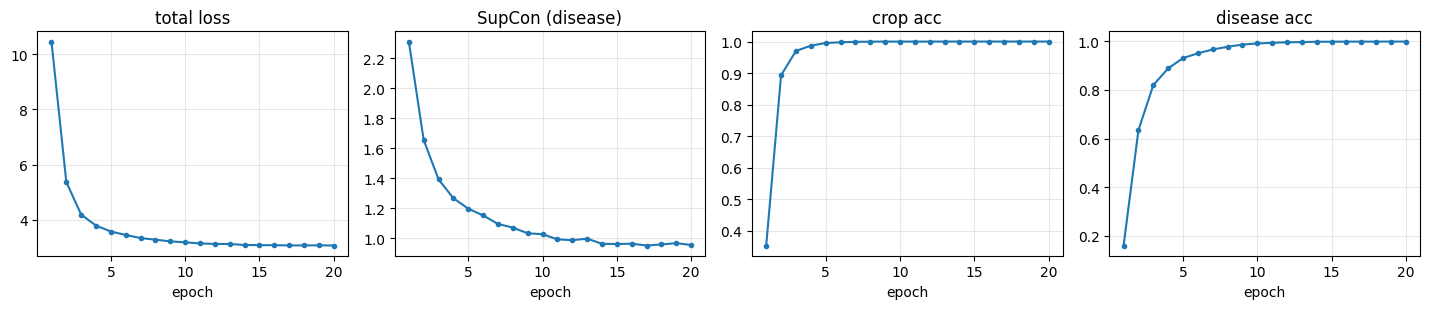

In [12]:
hist = pd.DataFrame(history)
panels = [('train_loss', 'total loss'), ('supcon_disease', 'SupCon (disease)'),
          ('train_crop_acc', 'crop acc'), ('train_disease_acc', 'disease acc')]
if CFG['run_mode'] == 'dev':
    panels += [('val_best_hm', 'val harmonic mean (best b)'), ('val_unseen_disease_acc', 'val-unseen disease acc')]
fig, axes = plt.subplots(1, len(panels), figsize=(3.6 * len(panels), 3.2))
for ax, (col, title) in zip(np.atleast_1d(axes), panels):
    ax.plot(hist['epoch'], hist[col], marker='o', ms=3)
    ax.set_title(title); ax.set_xlabel('epoch'); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'training_curves.png'), dpi=150); plt.show()

## 12. Dev summary
Saves the best epoch and bias for the final run.

In [13]:
if CFG['run_mode'] == 'dev':
    best = torch.load(BEST_CKPT, map_location=DEVICE, weights_only=False)
    model.load_state_dict(best['model'])
    vs, vu = run_inference(model, val_seen_loader), run_inference(model, val_unseen_loader)
    sweep = bias_sweep(comp_scores(vs), vs['comp'], comp_scores(vu), vu['comp'])
    summary = dict(best_epoch=best['epoch'], best_bias=sweep['best_bias'], val_best_hm=sweep['best_hm'],
                   val_seen_at_best=sweep['best_seen'], val_unseen_at_best=sweep['best_novel'],
                   val_auc=sweep['auc'], holdout_pairs=[COMP_NAMES[c] for c in HOLDOUT], cfg=CFG)
    json.dump(summary, open(DEV_SUMMARY, 'w'), indent=2)
    print(json.dumps({k: v for k, v in summary.items() if k != 'cfg'}, indent=2))

    plt.figure(figsize=(4.5, 4))
    plt.plot(sweep['seen'], sweep['novel'], '-')
    plt.scatter([sweep['best_seen']], [sweep['best_novel']], c='r', zorder=3, label=f"best H={sweep['best_hm']:.3f}")
    plt.xlabel('val-seen accuracy'); plt.ylabel('val-unseen (pseudo) accuracy'); plt.legend()
    plt.title(f"bias sweep (AUC {sweep['auc']:.3f})"); plt.grid(alpha=.3); plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, 'val_bias_curve.png'), dpi=150); plt.show()

In [14]:
if CFG['run_mode'] != 'final':
    raise SystemExit('Dev run finished. Set run_mode="final" in the config cell and Run all again.')

## 13. Test results
The reported row uses the dev bias. The oracle row is an upper bound only.

,bias,seen top-1,seen top-5,unseen top-1,unseen top-5,harmonic mean
b = 0 (no calibration),0.000000,71.95%,91.05%,3.94%,28.11%,7.46%
b from dev validation (REPORTED),5.314000,66.60%,88.80%,58.91%,95.79%,62.52%
oracle b on test (upper bound),6.135000,60.95%,87.65%,72.79%,96.96%,66.35%


seen/unseen AUC: 0.5581


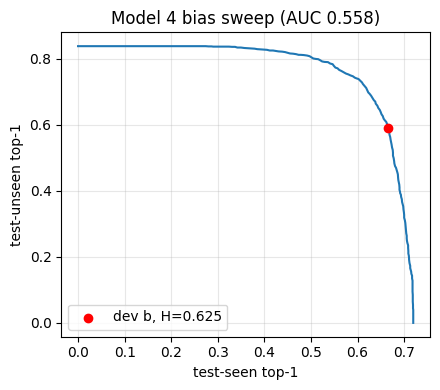

In [15]:
model.load_state_dict(torch.load(BEST_CKPT, map_location=DEVICE, weights_only=False)['model'])
ts = run_inference(model, make_loader(test_seen_df, train=False))
tu = run_inference(model, make_loader(test_unseen_df, train=False))
S_test, U_test = comp_scores(ts), comp_scores(tu)
DEV_BIAS = json.load(open(DEV_SUMMARY))['best_bias'] if os.path.exists(DEV_SUMMARY) else 0.0
test_sweep = bias_sweep(S_test, ts['comp'], U_test, tu['comp'])

def report(bias):
    s1, u1 = topk_acc(S_test, ts['comp'], 1, bias), topk_acc(U_test, tu['comp'], 1, bias)
    return {'bias': round(bias, 3), 'seen top-1': s1, 'seen top-5': topk_acc(S_test, ts['comp'], 5, bias),
            'unseen top-1': u1, 'unseen top-5': topk_acc(U_test, tu['comp'], 5, bias),
            'harmonic mean': harmonic_mean(s1, u1)}

results = pd.DataFrame({
    'b = 0 (no calibration)': report(0.0),
    'b from dev validation (REPORTED)': report(DEV_BIAS),
    'oracle b on test (upper bound)': report(test_sweep['best_bias']),
}).T
display(results.style.format({c: '{:.2%}' for c in results.columns if c != 'bias'}))
print(f"seen/unseen AUC: {test_sweep['auc']:.4f}")

plt.figure(figsize=(4.5, 4))
plt.plot(test_sweep['seen'], test_sweep['novel'], '-')
r = report(DEV_BIAS)
plt.scatter([r['seen top-1']], [r['unseen top-1']], c='r', zorder=3, label=f"dev b, H={r['harmonic mean']:.3f}")
plt.xlabel('test-seen top-1'); plt.ylabel('test-unseen top-1'); plt.legend(); plt.grid(alpha=.3)
plt.title(f"Model 4 bias sweep (AUC {test_sweep['auc']:.3f})"); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'test_bias_curve.png'), dpi=150); plt.show()

## 14. Paper protocol and shortcut rate
Crop and disease predicted independently, as in the DPD paper. Shortcut rate: share of wrong unseen disease predictions that name a disease the true crop had in training.

In [16]:
def paper_protocol(out):
    pc, pdis = out['crop_lp'].argmax(1), out['dis_lp'].argmax(1)
    return {'crop acc': (pc == out['crop']).float().mean().item(),
            'disease acc': (pdis == out['disease']).float().mean().item(),
            'crop+disease acc': ((pc == out['crop']) & (pdis == out['disease'])).float().mean().item()}

head_table = pd.DataFrame({'test-seen': paper_protocol(ts), 'test-unseen': paper_protocol(tu)}).T
display(head_table.style.format('{:.2%}'))
PAPER_HM = harmonic_mean(head_table.at['test-seen', 'crop+disease acc'], head_table.at['test-unseen', 'crop+disease acc'])
print(f'paper-protocol harmonic mean: {PAPER_HM:.2%}  '
      '(paper Table 4, full DPD, ViT-B/16: seen 78.53%, unseen 2.69%, HM 5.20%)')

train_pairs = set(zip(fit_df['crop'], fit_df['disease']))
pred_dis = tu['dis_lp'].argmax(1)
wrong = pred_dis != tu['disease']
shortcut = [(int(c), int(d)) in train_pairs for c, d in zip(tu['crop'][wrong], pred_dis[wrong])]
SHORTCUT_RATE = float(np.mean(shortcut)) if shortcut else 0.0
print(f'unseen images with the wrong disease: {int(wrong.sum())}/{len(wrong)}')
print(f'shortcut rate (wrong disease is one the true crop had in training): {SHORTCUT_RATE:.2%}')

,crop acc,disease acc,crop+disease acc
test-seen,93.10%,73.25%,70.90%
test-unseen,75.00%,9.12%,2.56%


paper-protocol harmonic mean: 4.93%  (paper Table 4, full DPD, ViT-B/16: seen 78.53%, unseen 2.69%, HM 5.20%)
unseen images with the wrong disease: 1316/1448
shortcut rate (wrong disease is one the true crop had in training): 70.90%


## 15. Confusion matrices and common mistakes

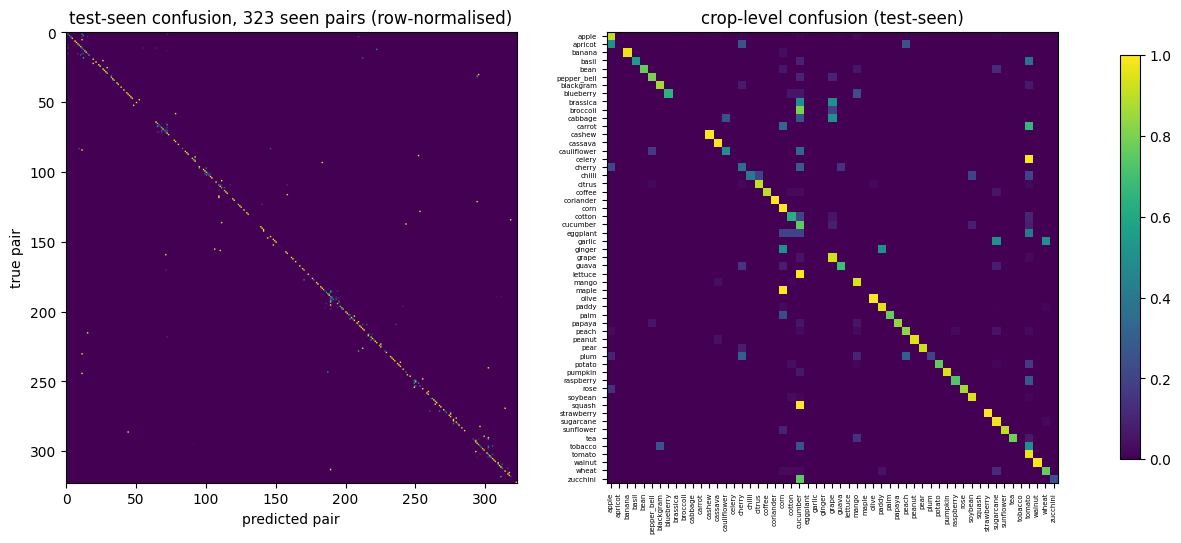

most confused seen pairs:


,true,predicted,count
0,paddy_healthy,paddy_blast,21
1,soybean_caterpillar,soybean_diabrotica_speciosa,12
2,cassava_brown_spot,cassava_bacterial_blight,11
3,tomato_bacterial_spot,tomato_early_blight,11
4,tomato_healthy,tomato_early_blight,10
5,potato_early_blight,tomato_early_blight,9
6,paddy_hispa,paddy_blast,9
7,soybean_healthy,soybean_caterpillar,9
8,tomato_septoria_leaf_spot,tomato_early_blight,9
9,corn_leaf_blight,corn_brown_spot,8


most common mistakes on unseen pairs (dev bias):


,true,predicted,same crop,count
0,tomato_early_blight,tomato_septoria_leaf_spot,True,82
1,grape_black_rot,grape_esca,True,67
2,tomato_early_blight,tomato_late_blight,True,66
3,pepper_bell_bacterial_spot,tomato_early_blight,False,45
4,grape_black_rot,mango_anthracnose,False,43
5,cotton_bacterial_blight,cotton_target_spot,True,26
6,sugarcane_rust,sugarcane_red_rot,True,17
7,tomato_early_blight,tomato_target_spot,True,17
8,tomato_early_blight,tomato_bacterial_spot,True,16
9,mango_anthracnose,mango_gall_midge,True,10


wrong unseen predictions that keep the right crop but pick the wrong disease: 59.2%


In [17]:
from sklearn.metrics import confusion_matrix
pred_seen = (S_test + DEV_BIAS * NOVEL_MASK.float()).argmax(1)
cm = confusion_matrix(ts['comp'].numpy(), pred_seen.numpy(), labels=list(range(NUM_COMPS)))
pd.DataFrame(cm, index=COMP_NAMES, columns=COMP_NAMES).to_csv(os.path.join(OUT_DIR, 'confusion_test_seen_pairs.csv'))

seen_ids = sorted(set(test_seen_df['comp']))
cm_seen = cm[np.ix_(seen_ids, seen_ids)].astype(float)
cm_norm = cm_seen / np.maximum(cm_seen.sum(1, keepdims=True), 1)
crop_cm = confusion_matrix(ts['crop'].numpy(), COMP_CROP[pred_seen].numpy(), labels=list(range(NUM_CROPS))).astype(float)
crop_norm = crop_cm / np.maximum(crop_cm.sum(1, keepdims=True), 1)

fig, axes = plt.subplots(1, 2, figsize=(16, 7.5))
axes[0].imshow(cm_norm, cmap='viridis', vmin=0, vmax=1)
axes[0].set_title(f'test-seen confusion, {len(seen_ids)} seen pairs (row-normalised)')
axes[0].set_xlabel('predicted pair'); axes[0].set_ylabel('true pair')
im = axes[1].imshow(crop_norm, cmap='viridis', vmin=0, vmax=1)
axes[1].set_title('crop-level confusion (test-seen)')
axes[1].set_xticks(range(NUM_CROPS)); axes[1].set_xticklabels(CROP_NAMES, rotation=90, fontsize=5)
axes[1].set_yticks(range(NUM_CROPS)); axes[1].set_yticklabels(CROP_NAMES, fontsize=5)
fig.colorbar(im, ax=axes, shrink=.7)
plt.savefig(os.path.join(OUT_DIR, 'confusion_test_seen.png'), dpi=200, bbox_inches='tight'); plt.show()

off = cm.copy(); np.fill_diagonal(off, 0)
top = np.dstack(np.unravel_index(np.argsort(off.ravel())[::-1][:15], off.shape))[0]
print('most confused seen pairs:')
display(pd.DataFrame([dict(true=COMP_NAMES[i], predicted=COMP_NAMES[j], count=int(off[i, j]))
                      for i, j in top if off[i, j] > 0]))

pred_unseen = (U_test + DEV_BIAS * NOVEL_MASK.float()).argmax(1)
unseen_errors = pd.DataFrame({'true': [COMP_NAMES[i] for i in tu['comp']],
                              'predicted': [COMP_NAMES[i] for i in pred_unseen],
                              'same crop': (COMP_CROP[pred_unseen] == tu['crop']).numpy()})
unseen_errors = unseen_errors[unseen_errors['true'] != unseen_errors['predicted']]
print('most common mistakes on unseen pairs (dev bias):')
display(unseen_errors.groupby(['true', 'predicted', 'same crop']).size().rename('count')
        .sort_values(ascending=False).head(15).reset_index())
print(f"wrong unseen predictions that keep the right crop but pick the wrong disease: {unseen_errors['same crop'].mean():.1%}")

## 16. Crop vs disease structure of the feature
Silhouette scores and t-SNE/UMAP of the 768-d feature, on test images whose disease is in an unseen pair.

1822 images | silhouette by crop 0.226 | by disease 0.224 (Baseline 2 ViT: 0.166 by crop, 0.175 by disease)


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


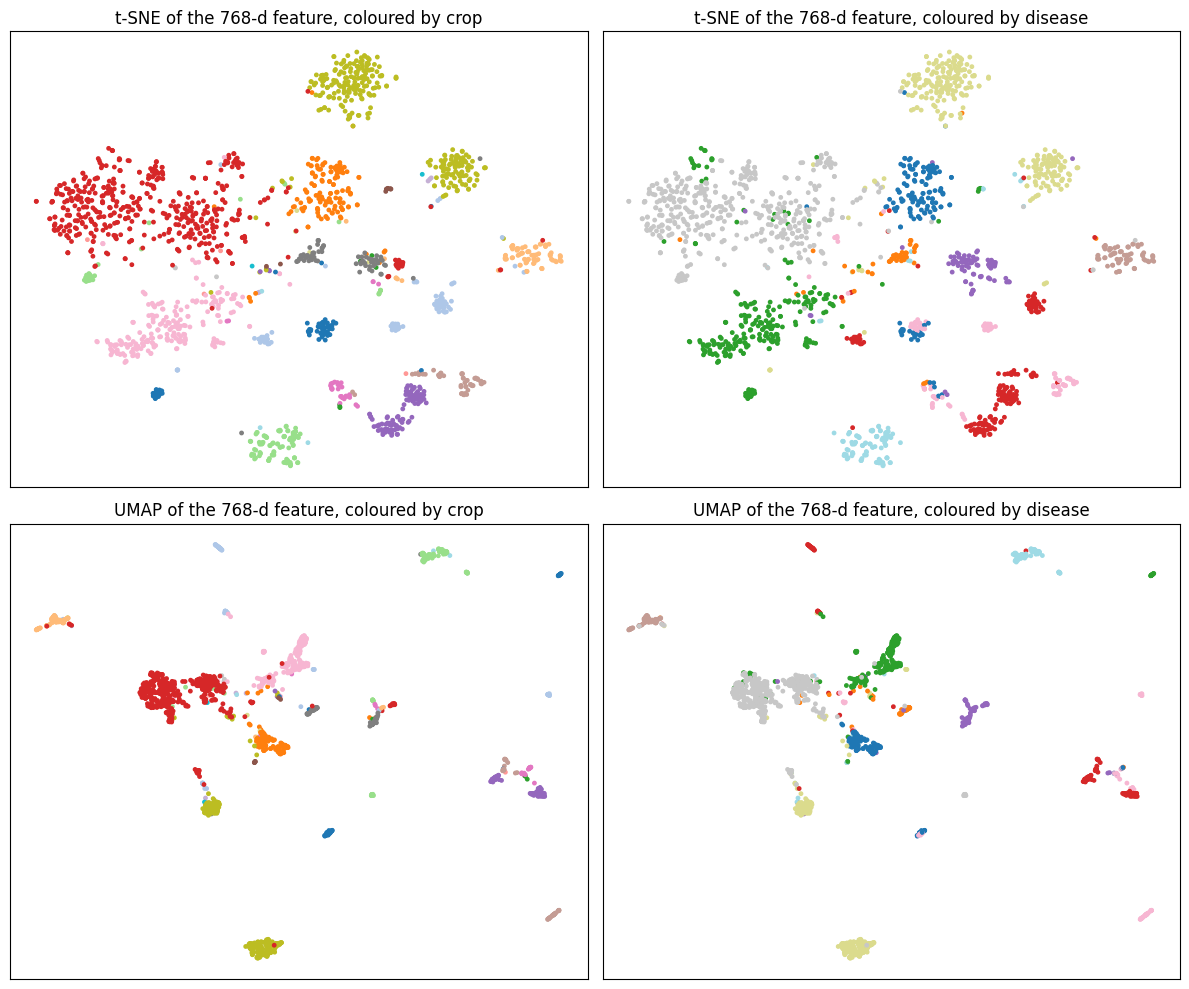

In [18]:
from sklearn.metrics import silhouette_score
from sklearn.manifold import TSNE

feat = F.normalize(torch.cat([ts['feat'], tu['feat']]), dim=1).numpy()
crop_lab = torch.cat([ts['crop'], tu['crop']]).numpy()
dis_lab = torch.cat([ts['disease'], tu['disease']]).numpy()
focus = np.isin(dis_lab, comps.loc[sorted(UNSEEN_COMPS), 'disease'].values)
f, c, d = feat[focus], crop_lab[focus], dis_lab[focus]

def safe_silhouette(x, y):
    return float(silhouette_score(x, y, metric='cosine')) if 1 < len(set(y)) < len(y) else float('nan')

SIL_CROP, SIL_DIS = safe_silhouette(f, c), safe_silhouette(f, d)
print(f'{focus.sum()} images | silhouette by crop {SIL_CROP:.3f} | by disease {SIL_DIS:.3f} '
      '(Baseline 2 ViT: 0.166 by crop, 0.175 by disease)')

if len(f) > 5:
    projections = {'t-SNE': TSNE(n_components=2, perplexity=min(30, len(f) - 1), init='pca',
                                 random_state=CFG['seed']).fit_transform(f)}
    try:
        import umap
        projections['UMAP'] = umap.UMAP(metric='cosine', random_state=CFG['seed']).fit_transform(f)
    except ImportError:
        print('umap-learn not installed: showing t-SNE only (pip install umap-learn to add UMAP)')
    fig, axes = plt.subplots(len(projections), 2, figsize=(12, 5 * len(projections)), squeeze=False)
    for row, (method, emb) in zip(axes, projections.items()):
        for ax, lab, name in ((row[0], c, 'crop'), (row[1], d, 'disease')):
            ax.scatter(emb[:, 0], emb[:, 1], c=pd.factorize(lab)[0], cmap='tab20', s=6)
            ax.set_title(f'{method} of the 768-d feature, coloured by {name}'); ax.set_xticks([]); ax.set_yticks([])
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'embedding_crop_vs_disease.png'), dpi=150); plt.show()

## 17. Save outputs
`eval_model.pt` (backbone, heads and dev bias, for `evaluate_baselines_2.ipynb`), `metrics.json`, and the feature bank for the UI.

In [19]:
bank = run_inference(model, make_loader(fit_df, train=False))
BANK_FEATS = F.normalize(bank['feat'], dim=1)
np.savez_compressed(os.path.join(OUT_DIR, 'feature_bank.npz'), feats=BANK_FEATS.numpy().astype(np.float16),
                    files=fit_df['file'].values, comp=bank['comp'].numpy(),
                    crop=bank['crop'].numpy(), disease=bank['disease'].numpy())

def export_eval_state_dict(model):
    keep = ('backbone.', 'crop_head.', 'disease_head.', 'crop_branch.', 'disease_branch.')
    return {k: v for k, v in model.state_dict().items() if k.startswith(keep)}

torch.save({'model': export_eval_state_dict(model), 'epoch': EPOCHS, 'bias': DEV_BIAS,
            'arch': 'multitask_vit_b16' if not CFG['branch_dim'] else 'multitask_vit_b16_branches'},
           os.path.join(OUT_DIR, 'eval_model.pt'))

metrics = dict(model='Model 4: single-stage joint SupCon + CE (multi-task ViT-B/16)', epochs=EPOCHS, dev_bias=DEV_BIAS,
               results={k: v for k, v in results.to_dict(orient='index').items()},
               auc=test_sweep['auc'], heads=head_table.to_dict(orient='index'),
               paper_protocol_hm=PAPER_HM, shortcut_rate=SHORTCUT_RATE, silhouette_crop=SIL_CROP, silhouette_disease=SIL_DIS,
               cfg=CFG)
json.dump(metrics, open(os.path.join(OUT_DIR, 'metrics.json'), 'w'), indent=2)
print('saved to', OUT_DIR, ':', sorted(os.listdir(OUT_DIR)))

saved to /content/drive/MyDrive/COS30082/outputs/model4_singlestage_supcon_vit/final : ['best.pt', 'confusion_test_seen.png', 'confusion_test_seen_pairs.csv', 'embedding_crop_vs_disease.png', 'eval_model.pt', 'feature_bank.npz', 'history.csv', 'last.pt', 'metrics.json', 'test_bias_curve.png', 'training_curves.png']


## 18. Demo — identify one image

true pair: pepper_bell_bacterial_spot


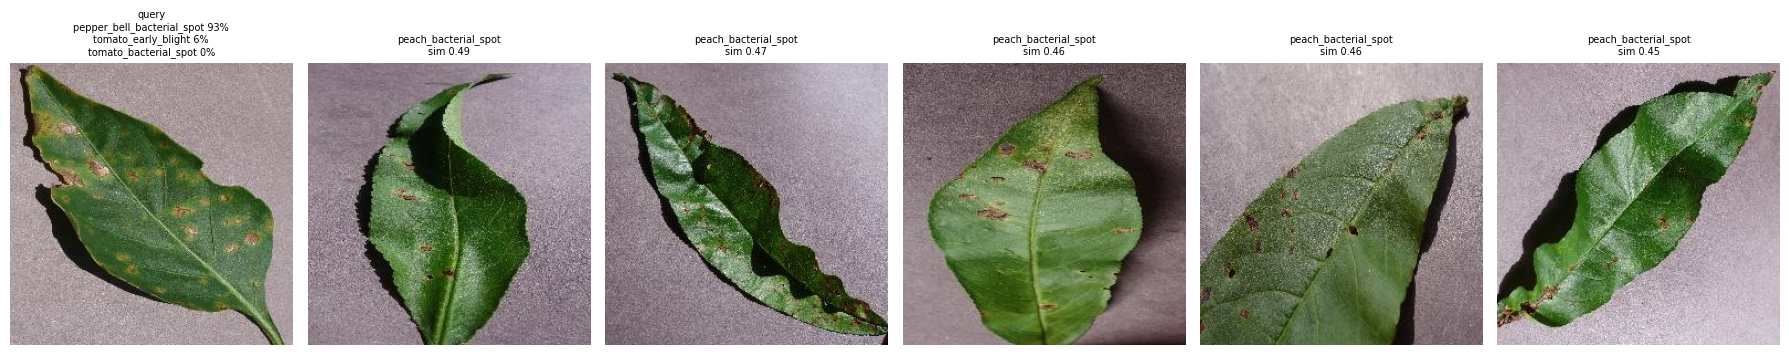

[('pepper_bell_bacterial_spot', 0.9275193214416504),
 ('tomato_early_blight', 0.06059021130204201),
 ('tomato_bacterial_spot', 0.0026982915587723255),
 ('peach_bacterial_spot', 0.00198155059479177),
 ('tomato_septoria_leaf_spot', 0.0019509680569171906)]

In [20]:
@torch.no_grad()
def identify(path, k=5, n_neighbours=5, bias=DEV_BIAS):
    model.eval()
    img = load_upright(path)
    lc, ld, feat = model(eval_tf(img)[None].to(DEVICE))
    s = F.log_softmax(lc.float(), 1).cpu()[0][COMP_CROP] + F.log_softmax(ld.float(), 1).cpu()[0][COMP_DIS]
    s = s + bias * NOVEL_MASK.float()
    probs = s.softmax(0)
    top = probs.topk(k)
    preds = [(COMP_NAMES[i], float(p)) for p, i in zip(top.values, top.indices)]
    sims = BANK_FEATS @ F.normalize(feat.float().cpu(), dim=1)[0]
    nn_idx = sims.topk(n_neighbours).indices.tolist()

    fig, axes = plt.subplots(1, n_neighbours + 1, figsize=(3 * (n_neighbours + 1), 3.4))
    axes[0].imshow(img); axes[0].set_title('query\n' + '\n'.join(f'{n} {p:.0%}' for n, p in preds[:3]), fontsize=7)
    for ax, i in zip(axes[1:], nn_idx):
        ax.imshow(Image.open(os.path.join(IMAGE_DIR, fit_df['file'].iloc[i])).convert('RGB'))
        ax.set_title(f"{COMP_NAMES[int(fit_df['comp'].iloc[i])]}\nsim {sims[i]:.2f}", fontsize=7)
    for ax in axes:
        ax.axis('off')
    plt.tight_layout(); plt.show()
    return preds

sample = test_unseen_df.iloc[0]
print('true pair:', sample['comp_name'])
identify(os.path.join(IMAGE_DIR, sample['file']))

## 19. Compare with the baselines
Reads every `outputs/*/final/metrics.json` on Drive.

In [21]:
import glob

def summary_row(name, m):
    rep = m['results']['b from dev validation (REPORTED)']
    unseen = m['heads']['test-unseen']
    return {'run': name, 'seen top-1': rep['seen top-1'], 'unseen top-1': rep['unseen top-1'],
            'unseen top-5': rep['unseen top-5'], 'harmonic mean': rep['harmonic mean'], 'AUC': m['auc'],
            'unseen crop acc': unseen['crop acc'], 'unseen disease acc': unseen['disease acc'],
            'paper-protocol HM': m['paper_protocol_hm'], 'shortcut rate': m['shortcut_rate']}

rows = []
for path in sorted(glob.glob(os.path.join(CFG['drive_root'], 'outputs', '*', 'final', 'metrics.json'))):
    name = os.path.basename(os.path.dirname(os.path.dirname(path)))
    try:
        rows.append(summary_row(name, json.load(open(path))))
    except (KeyError, TypeError, ValueError) as e:
        print('skipped', path, '-', e)
comparison = pd.DataFrame(rows).set_index('run')
pct = [c for c in comparison.columns if c != 'AUC']
display(comparison.style.format({**{c: '{:.2%}' for c in pct}, 'AUC': '{:.3f}'}))
comparison.to_csv(os.path.join(OUT_DIR, 'comparison_with_baselines.csv'))

,seen top-1,unseen top-1,unseen top-5,harmonic mean,AUC,unseen crop acc,unseen disease acc,paper-protocol HM,shortcut rate
run,,,,,,,,,
baseline2_multitask_resnet50,54.95%,41.92%,81.70%,47.56%,0.371,62.85%,5.66%,3.09%,57.39%
model4_singlestage_supcon_vit,66.60%,58.91%,95.79%,62.52%,0.558,75.00%,9.12%,4.93%,70.90%
